Se entregarán todos los ficheros de instrucciones (R o Python) y las presentaciones en un zip,
mediante la herramienta de mensaje de curso a Rafael Pino (se pueden generar archivos
.RMarkdown o bien Jupyter Notebook). Plazo de entrega: 6 de Abril.


Descargar los archivos datos.RData y GenerarDatos.R. Generar el conjunto de datos mediante las
instrucciones:
m= #cinco primeras cifras del DNI
source("../data/GenerarDatos.R")


Se obtendrá así un data frame de nombre datos, con 1000 casos, que contiene la variable label
(categórica distinguiendo dos tipos de prendas) y 10 variables potencialmente predictoras de label
(son el contenido de 10 píxeles entre los 784 píxeles en nivel de gris de cada imagen de resolución
28x28). También se habrá generado un subconjunto de datos, de nombre datosred, formado por 75
casos.
1) Trabajando con datosred, sin utilizar la variable label, aplicar e interpretar dos técnicas de
análisis de conglomerados,
2) Siguiendo también con datosred, configurar un modelo knn ponderado mediante validación
cruzada, y estimar la capacidad de generalización de dicho modelo mediante el método
bootstrap 632+.
3) A continuación, realizar una partición en subconjuntos de entrenamiento y test (75% y 25%)
de los 1000 casos de datos, que serán utilizados de forma conveniente. Construir un modelo
Naive-Bayes en el que se estimarán las funciones de densidad mediante el método núcleo.
Estimar la capacidad de generalización mediante los porcentajes de acierto global y para
cada categoría, así como la curva operativa característica y AUC

## Lectura de datos

In [9]:
with open("../data/GenerarDatos.R", "r") as file:
    content = file.read()

print(content)

#Seleccionar los datos
set.seed(m)
load(file="datos.RData")
dosprendas=sample(levels(datos$label),2)
diezvar=sort(sample(1:784,10)+1)
datos=datos[datos$label %in% dosprendas,c(1,diezvar)]
datos$label=factor(datos$label)
datos=datos[sample(nrow(datos),1000),]
datos[,-1]=datos[,-1]+matrix(runif(10000,0,5),ncol=10)
summary(datos)
datosred=datos[sample(nrow(datos),75),]




In [10]:
%pip install rpy2
%load_ext rpy2.ipython

Note: you may need to restart the kernel to use updated packages.
The rpy2.ipython extension is already loaded. To reload it, use:
  %reload_ext rpy2.ipython


You should consider upgrading via the 'c:\Users\migue\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [11]:
%%R
set.seed(29509)
load(file="../data/raw/datos.RData")
dosprendas=sample(levels(datos$label),2)
diezvar=sort(sample(1:784,10)+1)
datos=datos[datos$label %in% dosprendas,c(1,diezvar)]
datos$label=factor(datos$label)
datos=datos[sample(nrow(datos),1000),]
datos[,-1]=datos[,-1]+matrix(runif(10000,0,5),ncol=10)
summary(datos)
datosred=datos[sample(nrow(datos),75),]

## k-medias

In [12]:
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter

# Get R dataframe
r_df = ro.globalenv['datosred']

# Convert safely (non-deprecated)
with localconverter(ro.default_converter + pandas2ri.converter):
    datosred = ro.conversion.rpy2py(r_df)
print(datosred.head())

# Get R dataframe
r_df = ro.globalenv['datos']

# Convert safely (non-deprecated)
with localconverter(ro.default_converter + pandas2ri.converter):
    datos = ro.conversion.rpy2py(r_df)
print(datos.head())

            label     pixel52     pixel81    pixel125    pixel161    pixel211  \
13528  Ankle boot  201.793093  162.700873    4.234991  169.217817    4.142738   
22694  Ankle boot    0.069135    0.646734    0.004769  208.614096  218.208793   
5662     Pullover    0.286338    3.939923  182.829236  163.239230   15.796757   
14021    Pullover    0.222958    3.683458   41.547133   34.756743   42.617850   
57621    Pullover    2.483318    0.334995  242.553256   31.265694  129.676188   

         pixel528    pixel640    pixel668    pixel733  pixel745  
13528  174.981342  174.341084  173.088852  148.339451  1.203315  
22694  221.229079  207.903356  180.171668    1.457580  0.717407  
5662   207.927019  189.247633  188.271229   63.184415  1.426635  
14021  240.027298   32.046942   29.759892    3.856921  1.442612  
57621   28.705385   16.955517   13.718984    3.393077  2.482634  
            label   pixel52   pixel81    pixel125    pixel161    pixel211  \
20570    Pullover  3.157218  1.364506  2

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans

X = np.array(datosred.iloc[:, 1:].values)  # Exclude label column

# Create KMeans model
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

# Fit model
kmeans.fit(X)

# Get cluster labels
labels = kmeans.labels_

# Convert to DataFrame for easier handling
df = pd.DataFrame(X, columns=datosred.columns[1:])
df['cluster'] = labels
df['label'] = datosred['label'].values  

df.head()

ModuleNotFoundError: No module named 'matplotlib'

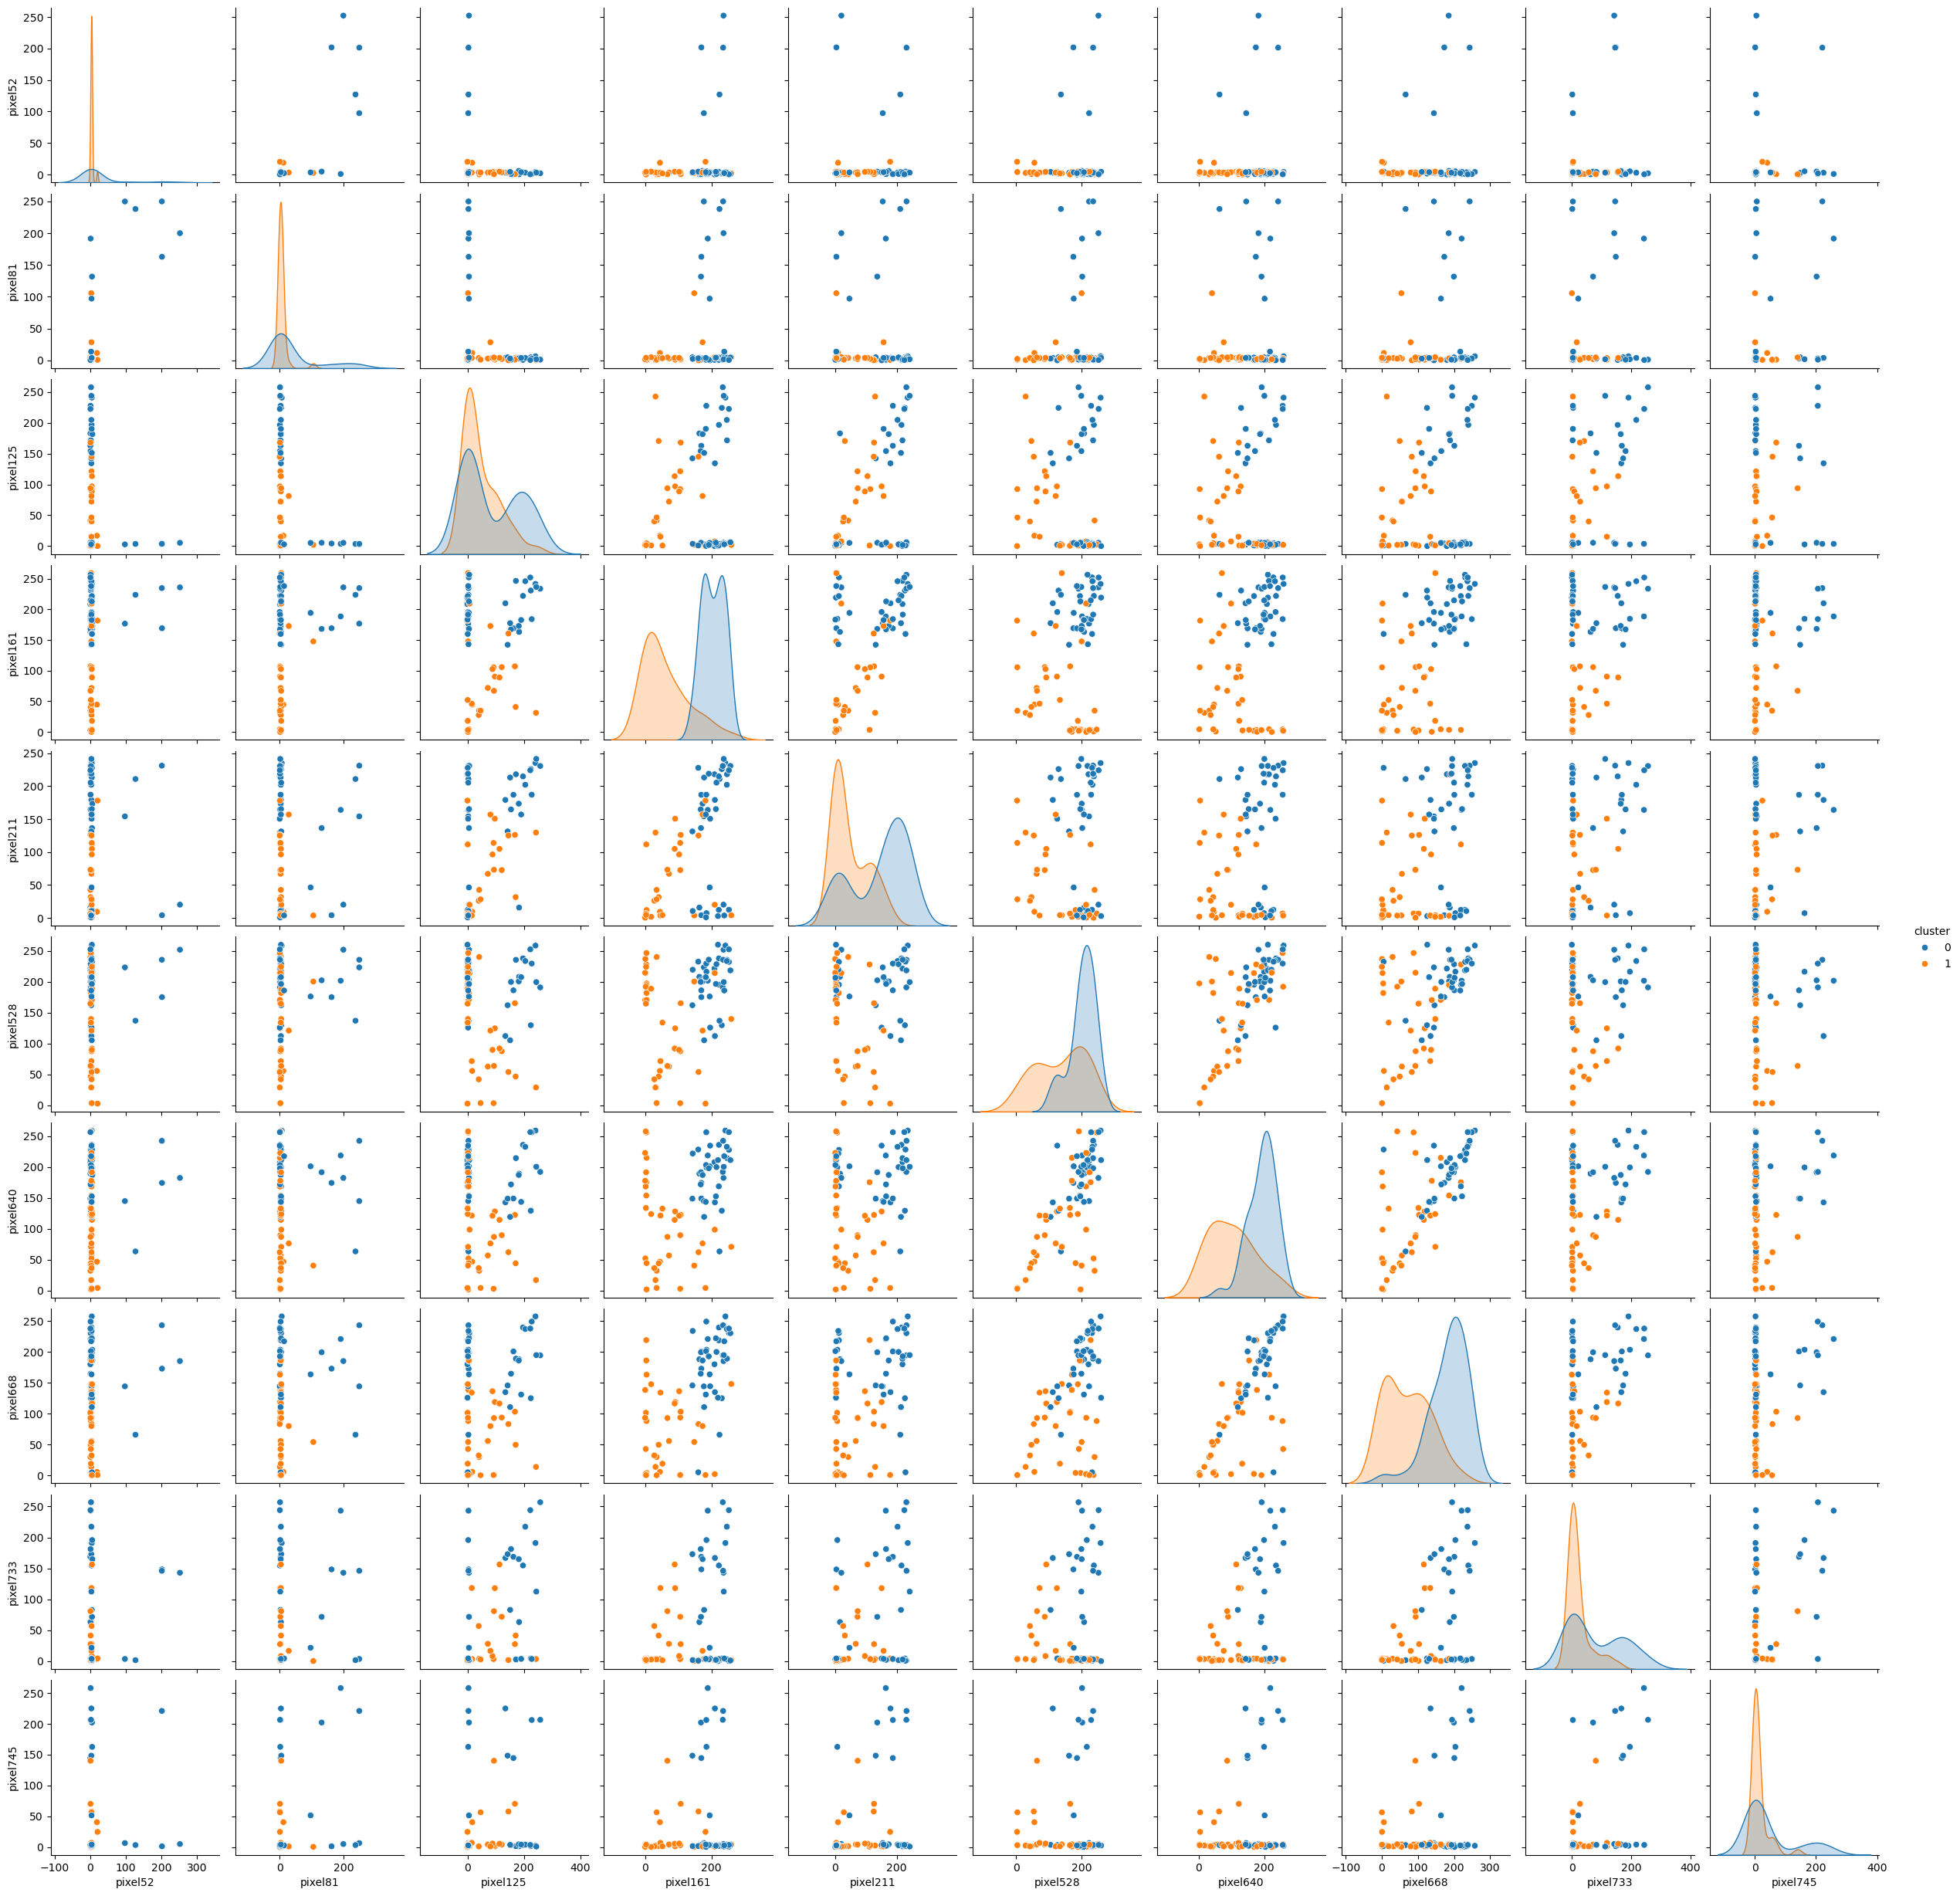

In [ ]:
#plotting covariables by two by two
import seaborn as sns
sns.pairplot(df, hue='cluster', vars=df.columns[:-1], )  # Exclude cluster column
plt.show()

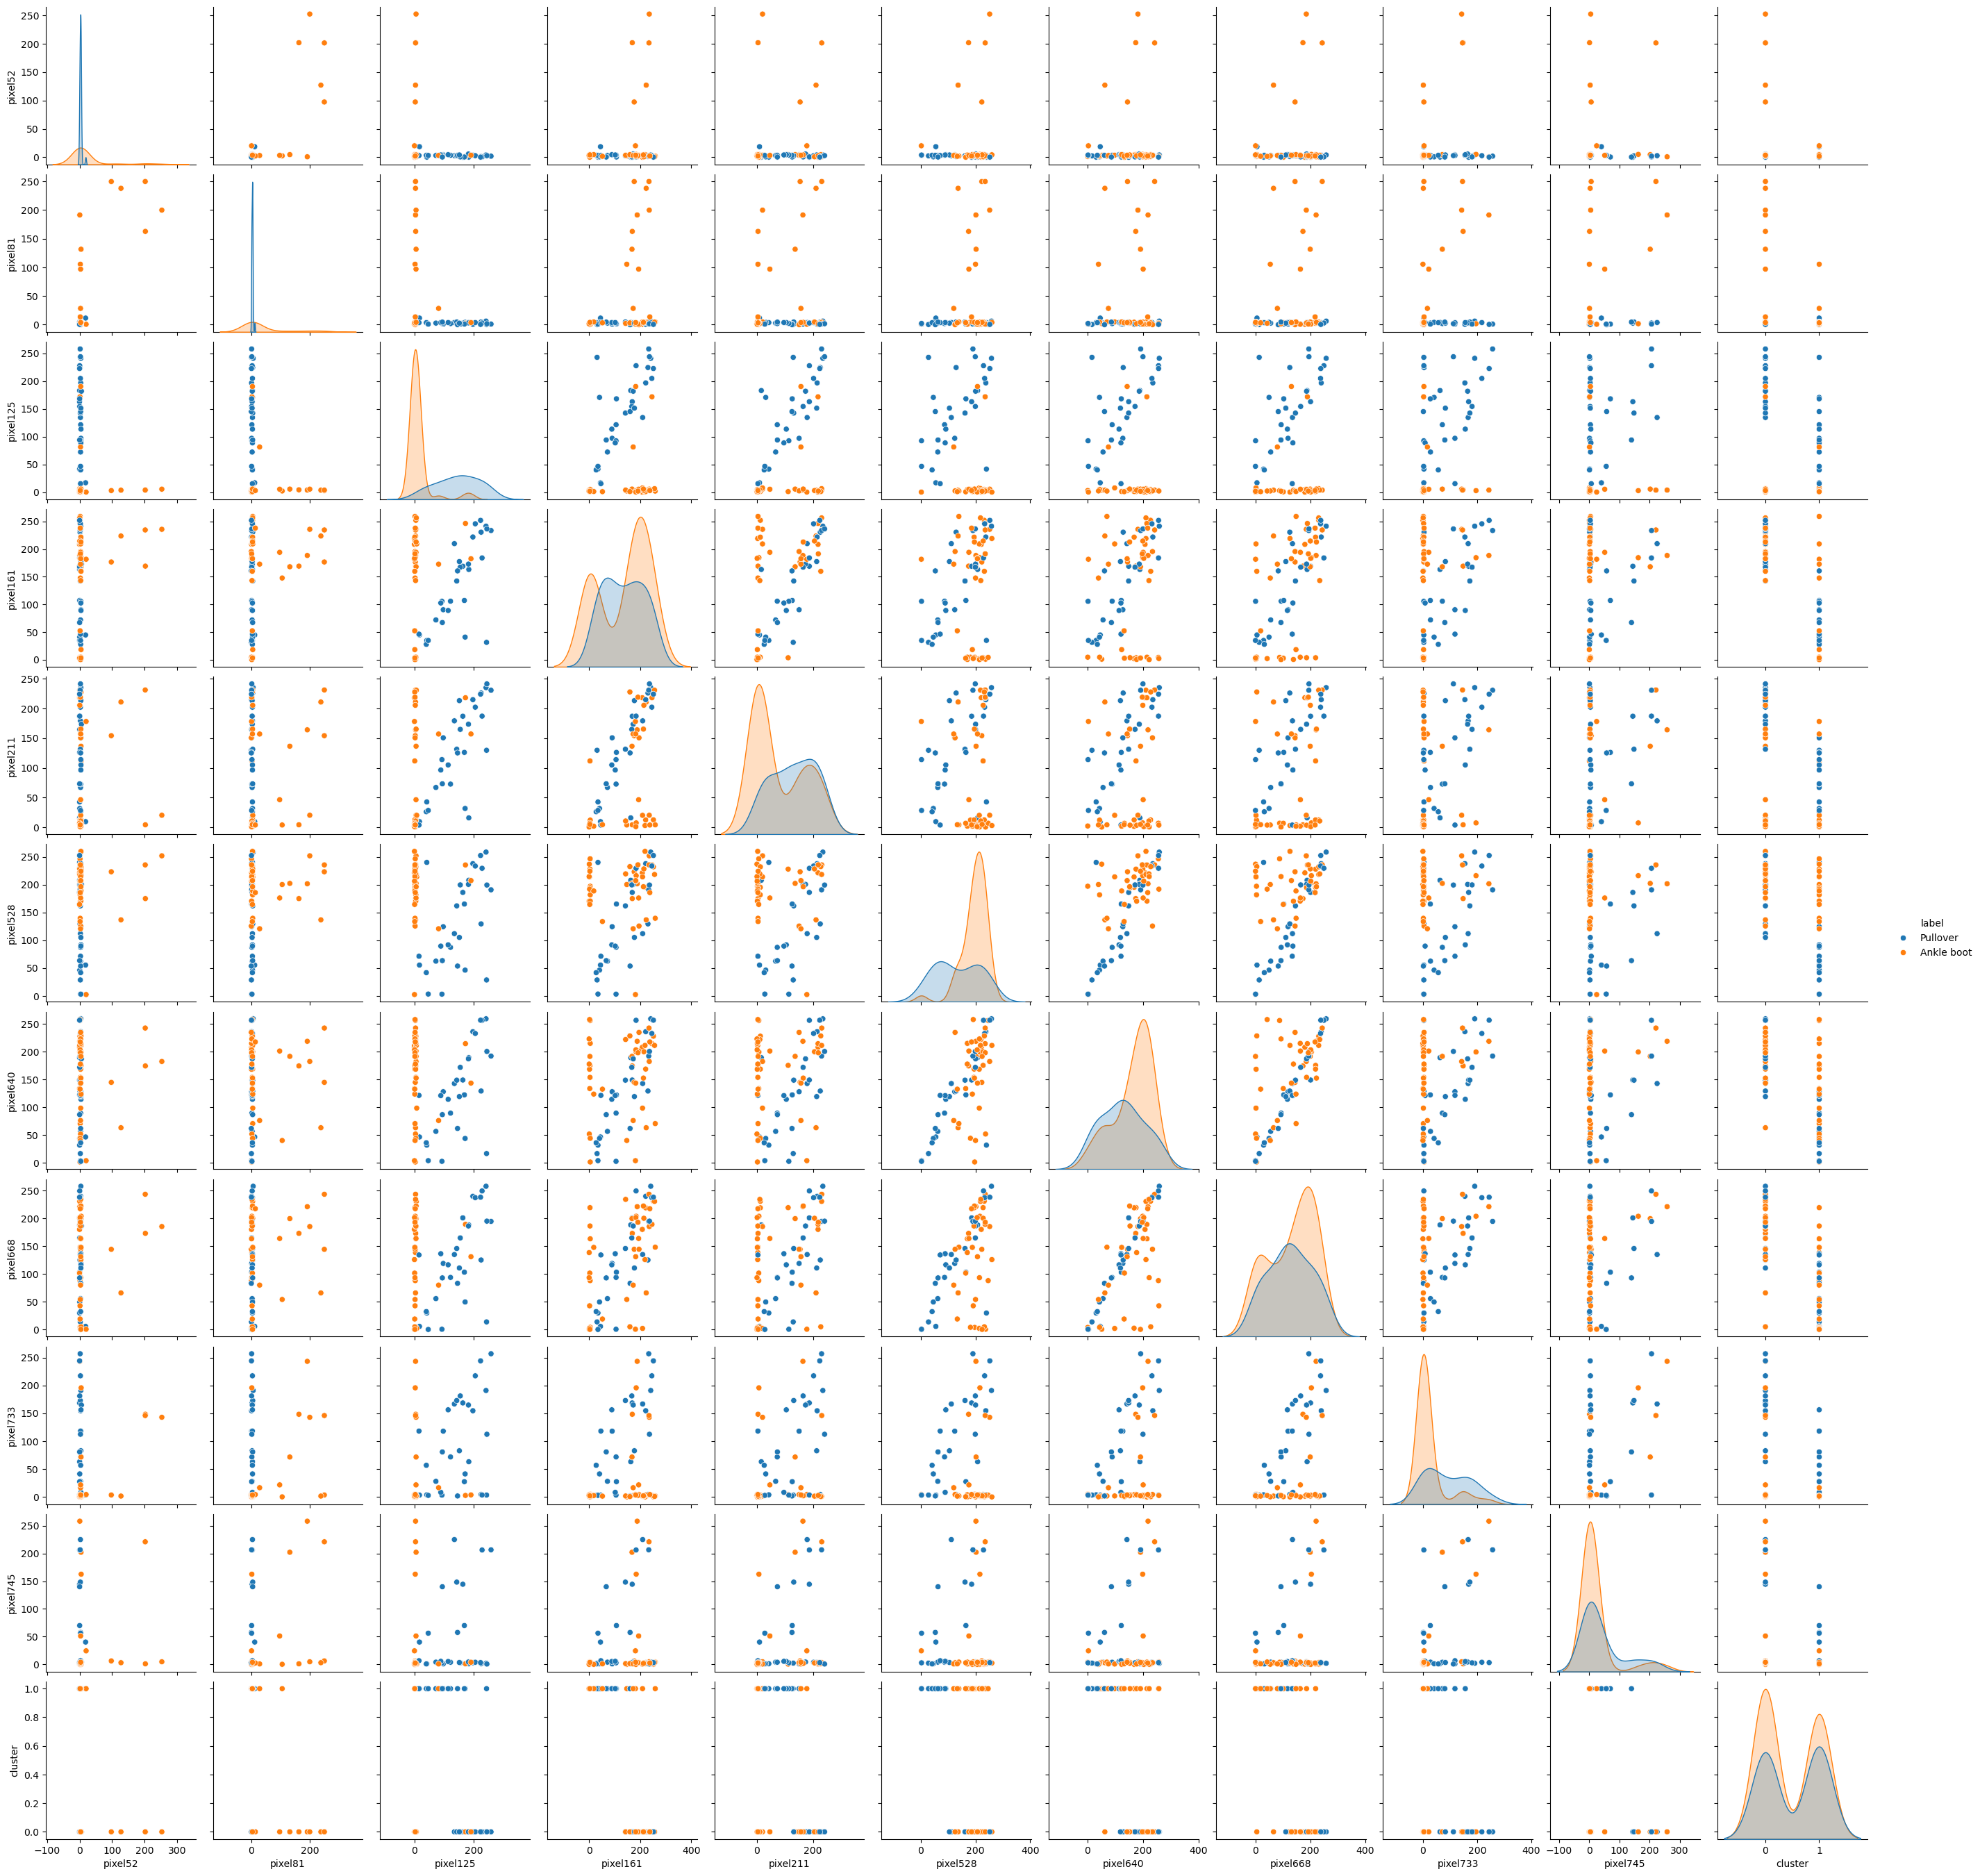

In [ ]:
#plotting covariables by two by two
import seaborn as sns
sns.pairplot(df, hue='label', vars=df.columns[:-1], )  # Exclude cluster column
plt.show()


# k-mediodes

In [14]:
%pip install scikit-learn-extra
%pip install scikit-learn
%pip install pandas
%pip install matplotlib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn_extra.cluster import KMedoids

# Scale data (important!)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit K-Medoids
kmedoids = KMedoids(n_clusters=2, random_state=42, method='pam')
kmedoids.fit(X_scaled)

labels = kmedoids.labels_

print(labels)

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\migue\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\migue\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\migue\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
You should consider upgrading via the 'c:\Users\migue\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


ValueError: numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject